## Load The Train-Test Split Data

In [2]:
import pandas as pd
import joblib
X_train, X_test, y_train, y_test = joblib.load(
    "../models/train_test_split.pkl"
)

## Import Tensorflow

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout
)

In [4]:
import pandas as pd
cancer_data=pd.read_csv(r"F:\Cancer AI Analyst\data\structured\processed\cancer_feature_engineered.csv")

In [5]:
from sklearn.model_selection import train_test_split

X=cancer_data.drop(
    "Target_Severity_Score",
    axis=1
)
y=cancer_data["Target_Severity_Score"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## Buliding Neural Network Architecture

In [6]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1)
])

## Compile the Model By Using Adam Optimizer

In [7]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [8]:
print(X_train.isnull().sum().sum())
print(y_train.isnull().sum())

8134
0


In [9]:
from sklearn.impute import SimpleImputer

imputer=SimpleImputer(strategy="most_frequent")

X_train["Stage_Severity"] = imputer.fit_transform(
    X_train[["Stage_Severity"]]
).ravel()

X_test["Stage_Severity"]=imputer.transform(
    X_test[["Stage_Severity"]]
).ravel()

In [10]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_train, X_test = X_train.align(
    X_test,
    join='left',
    axis=1,
    fill_value=0
)

In [11]:
print(X_train.isnull().sum().sum())
print(X_train.dtypes)

0
Age                           int64
Year                          int64
Genetic_Risk                float64
Air_Pollution               float64
Alcohol_Use                 float64
Smoking                     float64
Obesity_Level               float64
Treatment_Cost_USD          float64
Survival_Years              float64
Lifestyle_Risk_Score        float64
Overall_Risk_Score          float64
Stage_Severity              float64
Gender_Male                    bool
Gender_Other                   bool
Country_Region_Brazil          bool
Country_Region_Canada          bool
Country_Region_China           bool
Country_Region_Germany         bool
Country_Region_India           bool
Country_Region_Pakistan        bool
Country_Region_Russia          bool
Country_Region_UK              bool
Country_Region_USA             bool
Cancer_Type_Cervical           bool
Cancer_Type_Colon              bool
Cancer_Type_Leukemia           bool
Cancer_Type_Liver              bool
Cancer_Type_Lung          

In [12]:
print(X_train.dtypes)

Age                           int64
Year                          int64
Genetic_Risk                float64
Air_Pollution               float64
Alcohol_Use                 float64
Smoking                     float64
Obesity_Level               float64
Treatment_Cost_USD          float64
Survival_Years              float64
Lifestyle_Risk_Score        float64
Overall_Risk_Score          float64
Stage_Severity              float64
Gender_Male                    bool
Gender_Other                   bool
Country_Region_Brazil          bool
Country_Region_Canada          bool
Country_Region_China           bool
Country_Region_Germany         bool
Country_Region_India           bool
Country_Region_Pakistan        bool
Country_Region_Russia          bool
Country_Region_UK              bool
Country_Region_USA             bool
Cancer_Type_Cervical           bool
Cancer_Type_Colon              bool
Cancer_Type_Leukemia           bool
Cancer_Type_Liver              bool
Cancer_Type_Lung            

In [13]:
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

In [14]:
print(X_train.dtypes.unique())

[dtype('float32')]


In [15]:
print(X_train.shape)
print(y_train.shape)
print(X_train.dtypes.unique())

(40000, 42)
(40000,)
[dtype('float32')]


In [18]:
print(y_train.isnull().sum())

0


In [19]:
import numpy as np

print(np.isinf(X_train.values).sum())
print(np.isinf(y_train.values).sum())

0
0


In [21]:
import numpy as np

print("NaN in y_train:", np.isnan(y_train).sum())
print("Inf in y_train:", np.isinf(y_train).sum())

print("Min:", np.min(y_train))
print("Max:", np.max(y_train))

NaN in y_train: 0
Inf in y_train: 0
Min: 0.94
Max: 9.16


## Train The Model

In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential()

model.add(Dense(64, activation="relu", input_shape=(32,)))
model.add(Dense(32, activation="relu"))
model.add(Dense(16, activation="relu"))
model.add(Dense(1))

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

C:\Users\itibr\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# ==========================
# Load Dataset
# ==========================
cancer_data= pd.read_csv(r"F:\Cancer AI Analyst\data\structured\processed\cancer_feature_engineered.csv")

# ==========================
# Define Features & Target
# ==========================
X = cancer_data.drop("Target_Severity_Score", axis=1)
y = cancer_data["Target_Severity_Score"]

# ==========================
# Handle Categorical Columns
# ==========================
X = pd.get_dummies(X, drop_first=True)

# ==========================
# Train Test Split
# ==========================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# ==========================
# Feature Scaling
# ==========================
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ==========================
# Convert to float32
# ==========================
X_train_nn = X_train.astype("float32")
X_test_nn = X_test.astype("float32")

y_train_nn = y_train.to_numpy(dtype="float32")
y_test_nn = y_test.to_numpy(dtype="float32")

# ==========================
# Build ANN Model
# ==========================
model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_nn.shape[1],)),
    Dropout(0.3),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1)  # Regression Output
])

# ==========================
# Compile Model
# ==========================
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# ==========================
# Early Stopping
# ==========================
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# ==========================
# Train Model
# ==========================
history = model.fit(
    X_train_nn,
    y_train_nn,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# ==========================
# Evaluate Model
# ==========================
loss, mae = model.evaluate(
    X_test_nn,
    y_test_nn,
    verbose=0
)

print("Test MAE:", mae)

# ==========================
# Predictions
# ==========================
y_pred = model.predict(X_test_nn)

print(y_pred[:5])

C:\Users\itibr\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 7.5348 - mae: 2.0921 - val_loss: 1.4689 - val_mae: 0.9785
Epoch 2/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.6447 - mae: 1.0313 - val_loss: 1.4279 - val_mae: 0.9616
Epoch 3/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.5240 - mae: 0.9939 - val_loss: 1.4192 - val_mae: 0.9603
Epoch 4/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.4705 - mae: 0.9790 - val_loss: 1.4189 - val_mae: 0.9601
Epoch 5/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.4665 - mae: 0.9747 - val_loss: 1.4303 - val_mae: 0.9649
Epoch 6/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.4369 - mae: 0.9668 - val_loss: 1.4215 - val_mae: 0.9601
Epoch 7/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.4383 - mae: 0.9659 - val_loss: 1.4209 - val_mae: 0.9612
Epoch 8/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.4528 - mae: 0.9722 - val_loss: 1.4188 - val_mae: 0.9599
Epoch 9/100
1000/1000 ━━━━━━━━━━

## Calculate Metrics

In [35]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [38]:
import numpy as np
mae = mean_absolute_error(
    y_test,
    y_pred
)

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    y_pred
)

print("MAE :", mae)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 0.9590134183349608
RMSE: 1.1922592892259376
R2  : -0.0004326571492365705


## Learning Curve

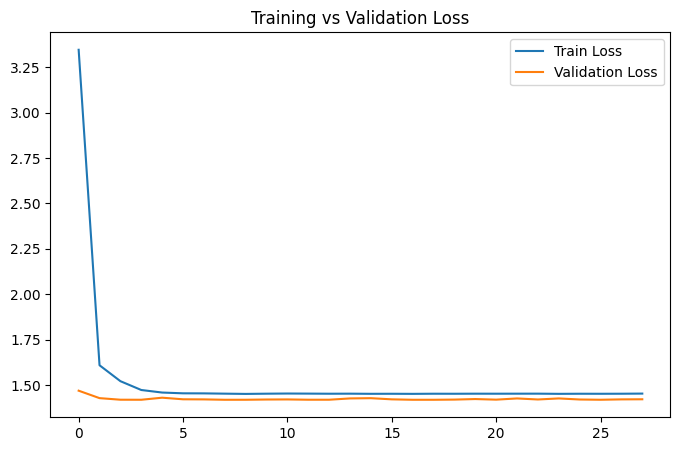

In [39]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(
    history.history["loss"],
    label="Train Loss"
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)
plt.legend()
plt.title(
    "Training vs Validation Loss"
)
plt.show()

## Save The Model

In [40]:
model.save(
    "../models/deep_learning_model.h5"
)

## Compare ML vs DL

In [41]:
comparison = pd.DataFrame({
    "Model":[
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost",
        "Deep Learning"
    ],
    "R2":[
        0.99999,
        0.99664,
        0.99806,
        0.99928,
        r2
    ]
})

comparison

,Model,R2
0,Linear Regression,0.999990
1,Random Forest,0.996640
2,Gradient Boosting,0.998060
3,XGBoost,0.999280
4,Deep Learning,-0.000433
